In [3]:
# Import libraries
import os
import re
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from collections import Counter
from tqdm.auto import tqdm

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
from google.colab import files
uploaded = files.upload()

Saving amazon_reviews.csv to amazon_reviews.csv


In [5]:
import pandas as pd

df = pd.read_csv('amazon_reviews.csv', encoding='latin1')

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (4915, 12)


,Unnamed: 0,reviewerName,overall,reviewText,reviewTime,day_diff,helpful_yes,helpful_no,total_vote,score_pos_neg_diff,score_average_rating,wilson_lower_bound
0,0,NaN,4.0,No issues.,2014-07-23,138,0,0,0,0,0.0,0.0
1,1,0mie,5.0,"Purchased this for my device, it worked as adv...",2013-10-25,409,0,0,0,0,0.0,0.0
2,2,1K3,4.0,it works as expected. I should have sprung for...,2012-12-23,715,0,0,0,0,0.0,0.0
3,3,1m2,5.0,This think has worked out great.Had a diff. br...,2013-11-21,382,0,0,0,0,0.0,0.0
4,4,2&amp;1/2Men,5.0,"Bought it with Retail Packaging, arrived legit...",2013-07-13,513,0,0,0,0,0.0,0.0


In [6]:
print(df.columns.tolist())

['Unnamed: 0', 'reviewerName', 'overall', 'reviewText', 'reviewTime', 'day_diff', 'helpful_yes', 'helpful_no', 'total_vote', 'score_pos_neg_diff', 'score_average_rating', 'wilson_lower_bound']


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4915 entries, 0 to 4914
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Unnamed: 0            4915 non-null   int64  
 1   reviewerName          4914 non-null   object 
 2   overall               4915 non-null   float64
 3   reviewText            4914 non-null   object 
 4   reviewTime            4915 non-null   object 
 5   day_diff              4915 non-null   int64  
 6   helpful_yes           4915 non-null   int64  
 7   helpful_no            4915 non-null   int64  
 8   total_vote            4915 non-null   int64  
 9   score_pos_neg_diff    4915 non-null   int64  
 10  score_average_rating  4915 non-null   float64
 11  wilson_lower_bound    4915 non-null   float64
dtypes: float64(3), int64(6), object(3)
memory usage: 460.9+ KB


In [8]:
print(df.isnull().sum())

Unnamed: 0              0
reviewerName            1
overall                 0
reviewText              1
reviewTime              0
day_diff                0
helpful_yes             0
helpful_no              0
total_vote              0
score_pos_neg_diff      0
score_average_rating    0
wilson_lower_bound      0
dtype: int64


In [9]:
# Check rating distribution
print(df["overall"].value_counts().sort_index())

overall
1.0     244
2.0      80
3.0     142
4.0     527
5.0    3922
Name: count, dtype: int64


In [10]:
# Data cleaning and preprocessing
df = df.dropna(subset=["reviewText", "overall"])

df["reviewText"] = df["reviewText"].astype(str)

df["overall"] = pd.to_numeric(
    df["overall"],
    errors="coerce"
)

df = df.dropna(subset=["overall"])

df = df[df["overall"].isin([1, 2, 3, 4, 5])]

df = df.drop_duplicates(
    subset=["reviewText", "overall"]
)

df = df.reset_index(drop=True)

print("Cleaned Dataset Shape:", df.shape)

Cleaned Dataset Shape: (4914, 12)


In [11]:
# Create sentiment labels
def convert_sentiment(rating):

    if rating <= 2:
        return 0

    elif rating == 3:
        return 1

    else:
        return 2


df["sentiment"] = df["overall"].apply(
    convert_sentiment
)

In [12]:
# Create label names
sentiment_mapping = {
    0: "Negative",
    1: "Neutral",
    2: "Positive"
}

df["sentiment_name"] = df["sentiment"].map(
    sentiment_mapping
)

print(df[["overall", "sentiment", "sentiment_name"]].head(10))

   overall  sentiment sentiment_name
0      4.0          2       Positive
1      5.0          2       Positive
2      4.0          2       Positive
3      5.0          2       Positive
4      5.0          2       Positive
5      5.0          2       Positive
6      5.0          2       Positive
7      5.0          2       Positive
8      5.0          2       Positive
9      5.0          2       Positive


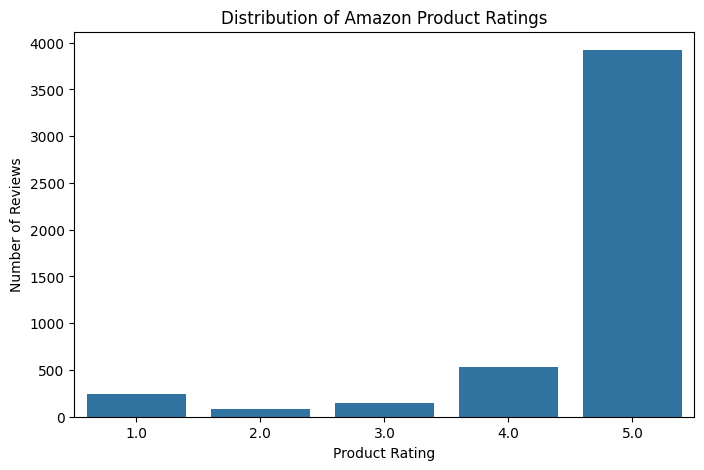

In [13]:
# Exploratory Data Analysis (EDA)
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="overall"
)

plt.title("Distribution of Amazon Product Ratings")
plt.xlabel("Product Rating")
plt.ylabel("Number of Reviews")

plt.savefig(
    r"C:\Users\Lucky Kashyap\Desktop\MLE\amazon-review-sentiment-analysis\results\rating_distribution.png",
    bbox_inches="tight"
)

plt.show()

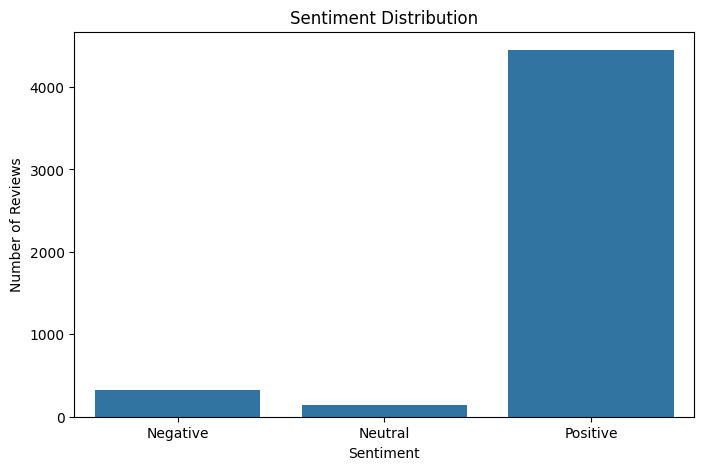

In [14]:
# Sentiment distribution
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="sentiment_name",
    order=["Negative", "Neutral", "Positive"]
)

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

sentiment_name
Positive    90.516891
Negative     6.593407
Neutral      2.889703
Name: count, dtype: float64


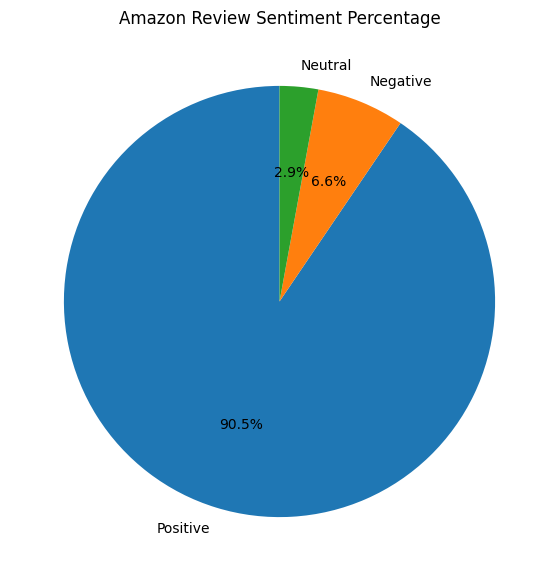

In [15]:
# Sentiment percentage
sentiment_counts = df["sentiment_name"].value_counts()

sentiment_percentage = (
    sentiment_counts / len(df)
) * 100

print(sentiment_percentage)

plt.figure(figsize=(7, 7))

plt.pie(
    sentiment_counts,
    labels=sentiment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Amazon Review Sentiment Percentage")

plt.show()

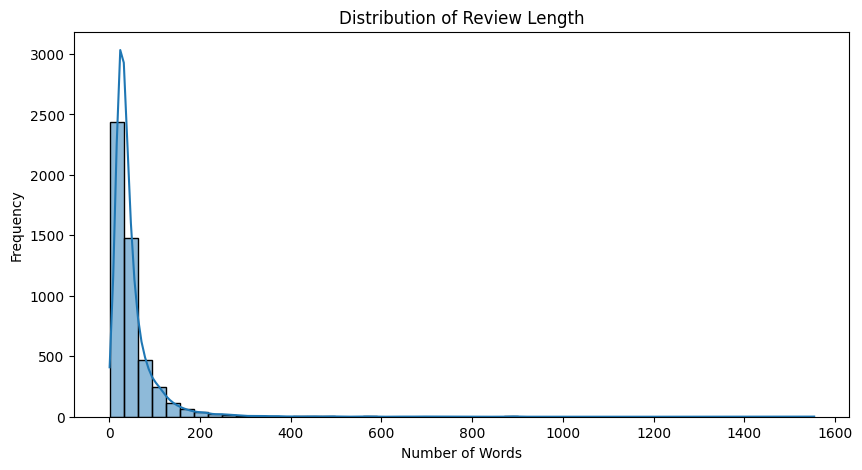

In [16]:
# Review length distribution
df["review_length"] = df["reviewText"].apply(
    lambda x: len(str(x).split())
)

plt.figure(figsize=(10, 5))

sns.histplot(
    df["review_length"],
    bins=50,
    kde=True
)

plt.title("Distribution of Review Length")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()

In [17]:
# Average review length by sentiment
print(
    df.groupby("sentiment_name")["review_length"]
    .mean()
)

sentiment_name
Negative    106.478395
Neutral      73.253521
Positive     45.643660
Name: review_length, dtype: float64


In [18]:
# Prepare training and testing data
# We will divide the dataset into:
# - 70% training data
# - 15% validation data
# - 15% testing data
MAX_SAMPLES = 50000

if len(df) > MAX_SAMPLES:

    df = df.sample(
        n=MAX_SAMPLES,
        random_state=42,
        stratify=df["sentiment"]
    )

X = df["reviewText"].astype(str)

y = df["sentiment"].astype(int)

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

Training samples: 3439
Validation samples: 737
Testing samples: 738


In [19]:
# Text preprocessing for LSTM
from collections import Counter

def clean_text(text):

    text = text.lower()

    text = re.sub(r"<.*?>", " ", text)

    text = re.sub(r"http\S+|www\S+", " ", text)

    text = re.sub(r"[^a-zA-Z0-9\s']", " ", text)

    text = re.sub(r"\s+", " ", text).strip()

    return text


train_texts = X_train.apply(clean_text).tolist()

val_texts = X_val.apply(clean_text).tolist()

test_texts = X_test.apply(clean_text).tolist()

In [20]:
# Create vocabulary
MAX_VOCAB = 30000

PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"

word_counts = Counter()

for text in train_texts:

    word_counts.update(text.split())

vocab = {
    PAD_TOKEN: 0,
    UNK_TOKEN: 1
}

for word, count in word_counts.most_common(
    MAX_VOCAB - 2
):

    vocab[word] = len(vocab)


print("Vocabulary Size:", len(vocab))

Vocabulary Size: 7383


In [21]:
# Convert words into numerical sequences
MAX_LEN = 128

def encode_text(text):

    tokens = text.split()

    ids = [
        vocab.get(word, vocab[UNK_TOKEN])
        for word in tokens[:MAX_LEN]
    ]

    return ids if ids else [vocab[UNK_TOKEN]]

In [22]:
# Create PyTorch dataset
class ReviewDataset(Dataset):

    def __init__(self, texts, labels):

        self.texts = [
            encode_text(text)
            for text in texts
        ]

        self.labels = labels.tolist()

    def __len__(self):

        return len(self.labels)

    def __getitem__(self, index):

        return (
            torch.tensor(self.texts[index], dtype=torch.long),
            torch.tensor(self.labels[index], dtype=torch.long)
        )

In [23]:
# Create a collate function to pad sequences
def collate_fn(batch):

    sequences, labels = zip(*batch)

    lengths = torch.tensor(
        [len(seq) for seq in sequences],
        dtype=torch.long
    )

    padded = nn.utils.rnn.pad_sequence(
        sequences,
        batch_first=True,
        padding_value=vocab[PAD_TOKEN]
    )

    labels = torch.stack(labels)

    return padded, lengths, labels

In [24]:
# Create DataLoaders
BATCH_SIZE = 64

train_dataset = ReviewDataset(
    train_texts,
    y_train
)

val_dataset = ReviewDataset(
    val_texts,
    y_val
)

test_dataset = ReviewDataset(
    test_texts,
    y_test
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn
)

In [25]:
# Define the LSTM model
class LSTMClassifier(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        hidden_dim=128,
        num_classes=3
    ):

        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=0
        )

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        self.dropout = nn.Dropout(0.3)

        self.fc = nn.Linear(
            hidden_dim,
            num_classes
        )

    def forward(self, x, lengths):

        embedded = self.embedding(x)

        packed = nn.utils.rnn.pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        _, (hidden, _) = self.lstm(packed)

        output = hidden[-1]

        output = self.dropout(output)

        return self.fc(output)

In [26]:
# Initialize the model
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

lstm_model = LSTMClassifier(
    vocab_size=len(vocab)
).to(device)

print(lstm_model)

LSTMClassifier(
  (embedding): Embedding(7383, 128, padding_idx=0)
  (lstm): LSTM(128, 128, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=3, bias=True)
)


In [27]:
# Train the LSTM model
class_counts = np.bincount(
    y_train,
    minlength=3
)

class_weights = len(y_train) / (
    3 * class_counts
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer = torch.optim.Adam(
    lstm_model.parameters(),
    lr=0.001
)

In [28]:
# Training function
def train_lstm_epoch(model, loader):

    model.train()

    total_loss = 0

    for sequences, lengths, labels in tqdm(loader):

        sequences = sequences.to(device)

        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(
            sequences,
            lengths
        )

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(loader)

In [29]:
# Evaluation function
def evaluate_lstm(model, loader):

    model.eval()

    predictions = []

    actual = []

    with torch.no_grad():

        for sequences, lengths, labels in loader:

            sequences = sequences.to(device)

            outputs = model(
                sequences,
                lengths
            )

            predicted = torch.argmax(
                outputs,
                dim=1
            )

            predictions.extend(
                predicted.cpu().numpy()
            )

            actual.extend(
                labels.numpy()
            )

    return np.array(actual), np.array(predictions)

In [30]:
# Train the model
LSTM_EPOCHS = 5

lstm_history = []

start_time = time.time()

for epoch in range(LSTM_EPOCHS):

    loss = train_lstm_epoch(
        lstm_model,
        train_loader
    )

    val_actual, val_predictions = evaluate_lstm(
        lstm_model,
        val_loader
    )

    val_accuracy = accuracy_score(
        val_actual,
        val_predictions
    )

    lstm_history.append({
        "epoch": epoch + 1,
        "loss": loss,
        "val_accuracy": val_accuracy
    })

    print(
        f"Epoch {epoch+1}/{LSTM_EPOCHS} | "
        f"Loss: {loss:.4f} | "
        f"Validation Accuracy: {val_accuracy:.4f}"
    )

lstm_training_time = time.time() - start_time

print(
    "LSTM Training Time:",
    round(lstm_training_time, 2),
    "seconds"
)

  0%|          | 0/54 [00:00<?, ?it/s]

Epoch 1/5 | Loss: 1.0888 | Validation Accuracy: 0.7218


  0%|          | 0/54 [00:00<?, ?it/s]

Epoch 2/5 | Loss: 1.0200 | Validation Accuracy: 0.8005


  0%|          | 0/54 [00:00<?, ?it/s]

Epoch 3/5 | Loss: 0.8288 | Validation Accuracy: 0.6852


  0%|          | 0/54 [00:00<?, ?it/s]

Epoch 4/5 | Loss: 0.6296 | Validation Accuracy: 0.6554


  0%|          | 0/54 [00:00<?, ?it/s]

Epoch 5/5 | Loss: 0.4238 | Validation Accuracy: 0.7856
LSTM Training Time: 4.36 seconds


In [31]:
# Save the model
os.makedirs("models", exist_ok=True)

torch.save(
    {
        "model_state_dict": lstm_model.state_dict(),
        "vocab": vocab,
        "max_len": MAX_LEN
    },
    "models/lstm_model.pth"
)

In [32]:
# Load pretrained BERT tokenizer
MODEL_NAME = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

print("BERT Tokenizer Loaded!")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

BERT Tokenizer Loaded!


In [33]:
# Tokenize the review dataset
BERT_MAX_LEN = 128

class BERTDataset(Dataset):

    def __init__(self, texts, labels):

        self.encodings = tokenizer(
            texts,
            truncation=True,
            padding="max_length",
            max_length=BERT_MAX_LEN,
            return_tensors="pt"
        )

        self.labels = torch.tensor(
            labels.tolist(),
            dtype=torch.long
        )

    def __len__(self):

        return len(self.labels)

    def __getitem__(self, index):

        item = {
            key: value[index]
            for key, value in self.encodings.items()
        }

        item["labels"] = self.labels[index]

        return item

In [34]:
# Create BERT datasets
bert_train_dataset = BERTDataset(
    X_train.tolist(),
    y_train
)

bert_val_dataset = BERTDataset(
    X_val.tolist(),
    y_val
)

bert_test_dataset = BERTDataset(
    X_test.tolist(),
    y_test
)

In [35]:
# Create DataLoaders
BERT_BATCH_SIZE = 16

bert_train_loader = DataLoader(
    bert_train_dataset,
    batch_size=BERT_BATCH_SIZE,
    shuffle=True
)

bert_val_loader = DataLoader(
    bert_val_dataset,
    batch_size=BERT_BATCH_SIZE
)

bert_test_loader = DataLoader(
    bert_test_dataset,
    batch_size=BERT_BATCH_SIZE
)

In [36]:
# Load pretrained BERT model
bert_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3
)

bert_model = bert_model.to(device)

print("BERT Model Loaded Successfully!")

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT Model Loaded Successfully!


In [37]:
# Define optimizer and loss
bert_class_weights = torch.tensor(
    class_weights.cpu().numpy(),
    dtype=torch.float32
).to(device)

bert_criterion = nn.CrossEntropyLoss(
    weight=bert_class_weights
)

bert_optimizer = torch.optim.AdamW(
    bert_model.parameters(),
    lr=2e-5
)

In [38]:
# Train BERT
def train_bert_epoch(model, loader):

    model.train()

    total_loss = 0

    for batch in tqdm(loader):

        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }

        bert_optimizer.zero_grad()

        outputs = model(
            input_ids=batch["input_ids"],
            attention_mask=batch["attention_mask"]
        )

        loss = bert_criterion(
            outputs.logits,
            batch["labels"]
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            1.0
        )

        bert_optimizer.step()

        total_loss += loss.item()

    return total_loss / len(loader)

In [39]:
# Evaluation function
def evaluate_bert(model, loader):

    model.eval()

    predictions = []

    actual = []

    with torch.no_grad():

        for batch in loader:

            batch = {
                key: value.to(device)
                for key, value in batch.items()
            }

            outputs = model(
                input_ids=batch["input_ids"],
                attention_mask=batch["attention_mask"]
            )

            predicted = torch.argmax(
                outputs.logits,
                dim=1
            )

            predictions.extend(
                predicted.cpu().numpy()
            )

            actual.extend(
                batch["labels"].cpu().numpy()
            )

    return np.array(actual), np.array(predictions)

In [40]:
# Training
BERT_EPOCHS = 2

bert_history = []

start_time = time.time()

for epoch in range(BERT_EPOCHS):

    loss = train_bert_epoch(
        bert_model,
        bert_train_loader
    )

    val_actual, val_predictions = evaluate_bert(
        bert_model,
        bert_val_loader
    )

    val_accuracy = accuracy_score(
        val_actual,
        val_predictions
    )

    bert_history.append({
        "epoch": epoch + 1,
        "loss": loss,
        "val_accuracy": val_accuracy
    })

    print(
        f"Epoch {epoch+1}/{BERT_EPOCHS} | "
        f"Loss: {loss:.4f} | "
        f"Validation Accuracy: {val_accuracy:.4f}"
    )

bert_training_time = time.time() - start_time

print(
    "BERT Training Time:",
    round(bert_training_time, 2),
    "seconds"
)

  0%|          | 0/215 [00:00<?, ?it/s]

Epoch 1/2 | Loss: 0.8767 | Validation Accuracy: 0.9362


  0%|          | 0/215 [00:00<?, ?it/s]

Epoch 2/2 | Loss: 0.7248 | Validation Accuracy: 0.9308
BERT Training Time: 161.22 seconds


In [41]:
# Save the fine-tuned BERT model
bert_model.save_pretrained(
    "models/bert_model"
)

tokenizer.save_pretrained(
    "models/bert_model"
)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('models/bert_model/tokenizer_config.json', 'models/bert_model/tokenizer.json')

In [42]:
# Evaluate LSTM
lstm_actual, lstm_predictions = evaluate_lstm(
    lstm_model,
    test_loader
)

print("LSTM Classification Report")

print(
    classification_report(
        lstm_actual,
        lstm_predictions,
        labels=[0, 1, 2],
        target_names=[
            "Negative",
            "Neutral",
            "Positive"
        ],
        zero_division=0
    )
)

LSTM Classification Report
              precision    recall  f1-score   support

    Negative       0.25      0.53      0.34        49
     Neutral       0.05      0.24      0.08        21
    Positive       0.96      0.76      0.85       668

    accuracy                           0.73       738
   macro avg       0.42      0.51      0.42       738
weighted avg       0.89      0.73      0.80       738



In [43]:
# Evaluate BERT
bert_actual, bert_predictions = evaluate_bert(
    bert_model,
    bert_test_loader
)

print("BERT Classification Report")

print(
    classification_report(
        bert_actual,
        bert_predictions,
        labels=[0, 1, 2],
        target_names=[
            "Negative",
            "Neutral",
            "Positive"
        ],
        zero_division=0
    )
)

BERT Classification Report
              precision    recall  f1-score   support

    Negative       0.56      0.92      0.69        49
     Neutral       0.00      0.00      0.00        21
    Positive       0.98      0.96      0.97       668

    accuracy                           0.93       738
   macro avg       0.51      0.63      0.55       738
weighted avg       0.93      0.93      0.93       738



In [44]:
# Calculate evaluation metrics
def calculate_metrics(actual, predicted):

    return {
        "Accuracy": accuracy_score(
            actual,
            predicted
        ),

        "Precision": precision_score(
            actual,
            predicted,
            average="macro",
            zero_division=0
        ),

        "Recall": recall_score(
            actual,
            predicted,
            average="macro",
            zero_division=0
        ),

        "F1 Score": f1_score(
            actual,
            predicted,
            average="macro",
            zero_division=0
        )
    }


lstm_metrics = calculate_metrics(
    lstm_actual,
    lstm_predictions
)

bert_metrics = calculate_metrics(
    bert_actual,
    bert_predictions
)

comparison = pd.DataFrame(
    [lstm_metrics, bert_metrics],
    index=["LSTM", "BERT"]
)

print(comparison)

      Accuracy  Precision    Recall  F1 Score
LSTM  0.733062   0.418856  0.510727  0.422735
BERT  0.930894   0.512402  0.626482  0.554521


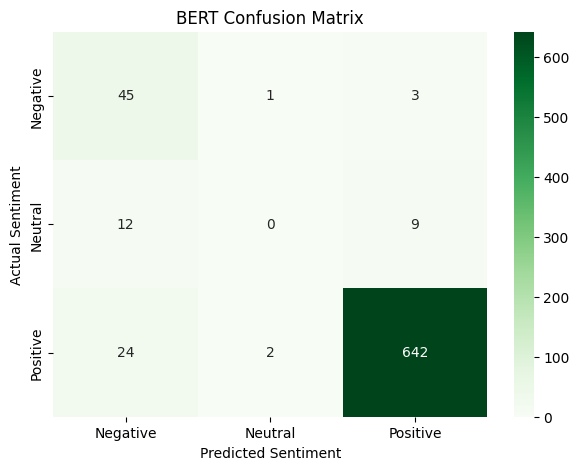

In [47]:
# BERT confusion matrix
cm_bert = confusion_matrix(
    bert_actual,
    bert_predictions,
    labels=[0, 1, 2]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_bert,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=[
        "Negative",
        "Neutral",
        "Positive"
    ],
    yticklabels=[
        "Negative",
        "Neutral",
        "Positive"
    ]
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

plt.title("BERT Confusion Matrix")

plt.savefig(
    r"C:\Users\Lucky Kashyap\Desktop\MLE\amazon-review-sentiment-analysis\results\confusion_matrix_bert.png",
    bbox_inches="tight"
)

plt.show()

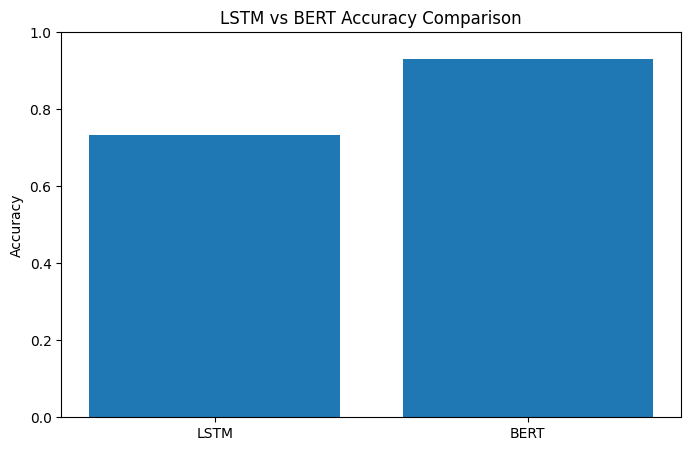

In [48]:
# Compare model accuracy
plt.figure(figsize=(8, 5))

accuracy_values = [
    lstm_metrics["Accuracy"],
    bert_metrics["Accuracy"]
]

plt.bar(
    ["LSTM", "BERT"],
    accuracy_values
)

plt.ylabel("Accuracy")

plt.title("LSTM vs BERT Accuracy Comparison")

plt.ylim(0, 1)

plt.savefig(
    r"C:\Users\Lucky Kashyap\Desktop\MLE\amazon-review-sentiment-analysis\results\model_accuracy_comparison.png",
    bbox_inches="tight"
)

plt.show()

  Model  Training Time (seconds)
0  LSTM                 4.360767
1  BERT               161.222235


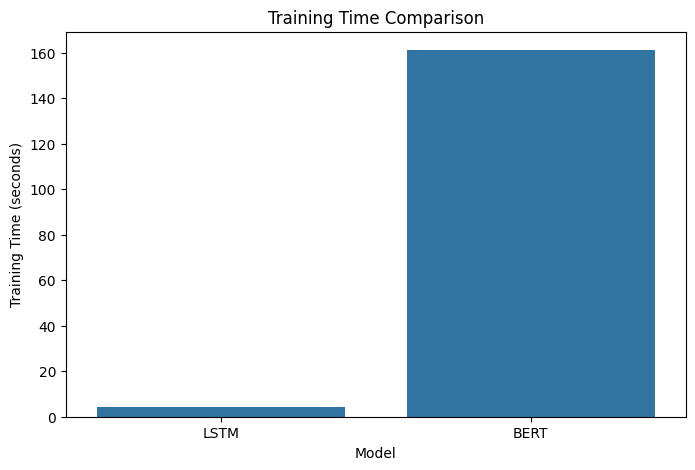

In [50]:
# Compare training time
training_times = pd.DataFrame({
    "Model": ["LSTM", "BERT"],
    "Training Time (seconds)": [
        lstm_training_time,
        bert_training_time
    ]
})

print(training_times)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=training_times,
    x="Model",
    y="Training Time (seconds)"
)

plt.title("Training Time Comparison")

plt.show()

In [51]:
# Final comparison table
final_comparison = comparison.copy()

final_comparison["Training Time (seconds)"] = [
    lstm_training_time,
    bert_training_time
]

print("\nFINAL MODEL COMPARISON\n")

print(
    final_comparison.round(4)
)


FINAL MODEL COMPARISON

      Accuracy  Precision  Recall  F1 Score  Training Time (seconds)
LSTM    0.7331     0.4189  0.5107    0.4227                   4.3608
BERT    0.9309     0.5124  0.6265    0.5545                 161.2222


In [52]:
# BERT prediction function
def predict_sentiment_bert(review):

    bert_model.eval()

    inputs = tokenizer(
        review,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=128
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():

        outputs = bert_model(**inputs)

        probabilities = torch.softmax(
            outputs.logits,
            dim=1
        )

        prediction = torch.argmax(
            probabilities,
            dim=1
        ).item()

    labels = {
        0: "Negative",
        1: "Neutral",
        2: "Positive"
    }

    return {
        "sentiment": labels[prediction],
        "confidence": round(
            probabilities[0][prediction].item() * 100,
            2
        )
    }

In [53]:
# Test the model
sample_reviews = [
    "This product is amazing. I absolutely love it!",

    "The product is okay, nothing special.",

    "Very poor quality. I regret buying this product."
]

for review in sample_reviews:

    result = predict_sentiment_bert(review)

    print("\nReview:", review)

    print("Predicted Sentiment:", result["sentiment"])

    print("Confidence:", result["confidence"], "%")


Review: This product is amazing. I absolutely love it!
Predicted Sentiment: Positive
Confidence: 99.63 %

Review: The product is okay, nothing special.
Predicted Sentiment: Positive
Confidence: 98.45 %

Review: Very poor quality. I regret buying this product.
Predicted Sentiment: Negative
Confidence: 95.13 %
